<font face="Times New Roman" size=5>
<div dir=rtl align="center">
<font face="Times New Roman" size=5>
In The Name of God
</font>
<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Electrical Engineering Department
</font>
<br>
<font color="#008080" size=6>
Probability and Statistics
</font>
<hr/>
<font color="#800080" size=5>
Assignment 1
<br>
</font>
<font size=5>
Instructor: Dr. Yassaee
<br>
</font>
<font size=4>
Fall 2025
<br>
</font>
<font face="Times New Roman" size=4>
Deadline: 7 Azar 1404
</font>
<hr>
<br>
</font>
<font face="Times New Roman" size=4 align=center>
Feel free to ask your questions in Telegram : @Ali99os
</font>
<br>
<hr>
</div></font>

In [ ]:
Name = "Seyed Kiarash Eshraghi"
StudentId = "403101383"

# Import Libraries

In [ ]:
### add your libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Question 1

## Waiting for the Perfect Sunset

Every evening, tourists gather at a beach to photograph the sunset.
The time (in minutes after 6:00 PM) at which the “perfect light” occurs is a **continuous random variable** ( $X$ ) that follows an **exponential distribution** with rate parameter $( \lambda = 0.2 )$ (i.e., average waiting time 5 minutes).



### **Part (a): Understanding the Model**

1. Write down the **probability density function (pdf)** and **cumulative distribution function (cdf)** for ( $X$ ).
2. Plot both pdf and cdf for ( $X$ ) on the same time axis from 0 to 20 minutes.

   * Label the mean waiting time and shade the probability that the “perfect light” happens within the first 3 minutes.


Answer:

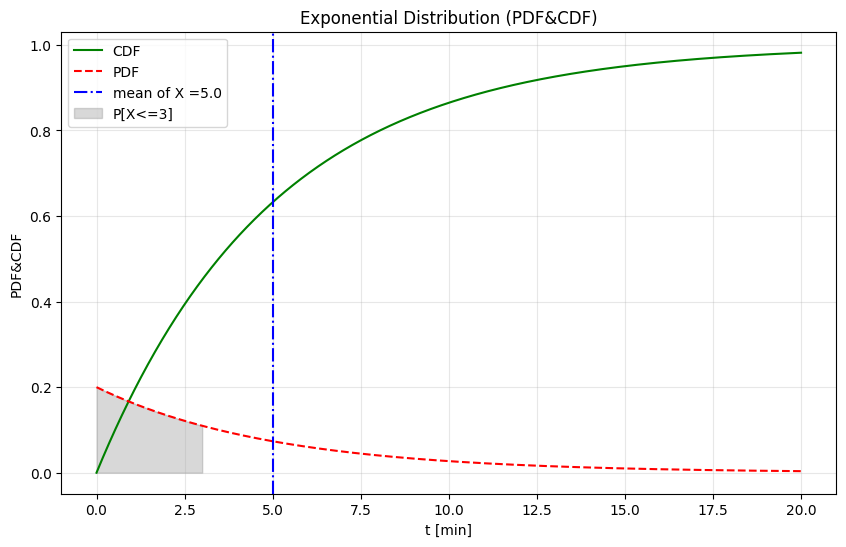

In [6]:
# code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
lambda_val =0.2
t=np.linspace(0,20,1000)
cdf=1-np.exp(-1*lambda_val *t)
pdf=lambda_val*np.exp(-1*lambda_val *t)
plt.figure(figsize=(10,6))
plt.plot(t,cdf,label="CDF",color='green')
plt.plot(t,pdf,label="PDF",color='red',linestyle='--')
mean=1.0/lambda_val
plt.axvline(x=mean,color='blue',linestyle='-.',label=f'mean of X ={mean}')
t_shade=np.linspace(0,3,100)
pdf_shade=lambda_val*np.exp(-lambda_val*t_shade)
plt.fill_between(t_shade,pdf_shade,color='gray',alpha=0.3,label='P[X<=3]')
plt.title('Exponential Distribution (PDF&CDF)')
plt.xlabel('t [min]')
plt.ylabel('PDF&CDF')
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()


### **Part (b): Probability Analysis**

1. Compute the probability that:

   * the perfect light occurs **after 10 minutes**,
   * the perfect light occurs **between 3 and 8 minutes**,
   * and the **median** waiting time (the time by which half of the evenings have had perfect light).
2. Verify the analytical results using **simulation**: generate 10 000 samples of ( $X$ ) and estimate the same probabilities empirically.


Answer:

In [5]:
# code here
N=10000
P_X_greater_10=np.exp(-1*lambda_val*10)
P_X_between_3_8=np.exp(-1*lambda_val*3)-np.exp(-1*lambda_val*8)
m=np.log(2)/lambda_val
print("result from analysis:\n")
print(f"P[X>10]={P_X_greater_10:.4f}\n")
print(f"P[3<X<8]={P_X_between_3_8:.4f}\n")
print(f"Median={m:.4f}\n")
print("-"*40)
s=np.random.exponential(scale=1/lambda_val,size=N)
P_X_greater_10_from_simulation=np.sum(s>10)/N
P_X_between_3_8_from_simulation=np.sum((s>3)&(s<8))/N
m_from_simulation=np.median(s)
print("result from simulation:\n")
print(f"P[X>10]={P_X_greater_10_from_simulation:.4f}\n")
print(f"P[3<X<8]={P_X_between_3_8_from_simulation:.4f}\n")
print(f"Median={m_from_simulation:.4f}\n")

result from analysis:

P[X>10]=0.1353

P[3<X<8]=0.3469

Median=3.4657

----------------------------------------
result from simulation:

P[X>10]=0.1323

P[3<X<8]=0.3388

Median=3.3402



### **Part (c): Competing Photographers**

Now imagine two photographers:

* **Alice** sets up her camera at 6:00 PM, waiting for the perfect light (distributed as ( $X_1 \sim \text{Exponential}(0.2)$ )).
* **Bob**, more patient, only arrives at 6:02 PM, and his waiting time ( $X_2$ ) (from his arrival) follows the **Uniform(0, 10)** distribution.

1. Simulate 10 000 evenings and estimate:

   * the probability that **Alice captures the perfect light before Bob**,
   * the **expected difference** in their waiting times.
2. Plot a histogram of both waiting times to visualize the comparison.

Answer:

P_Alice_wins=0.7121

mean_of_diff_of_t_Alice_Bob=-2.0035



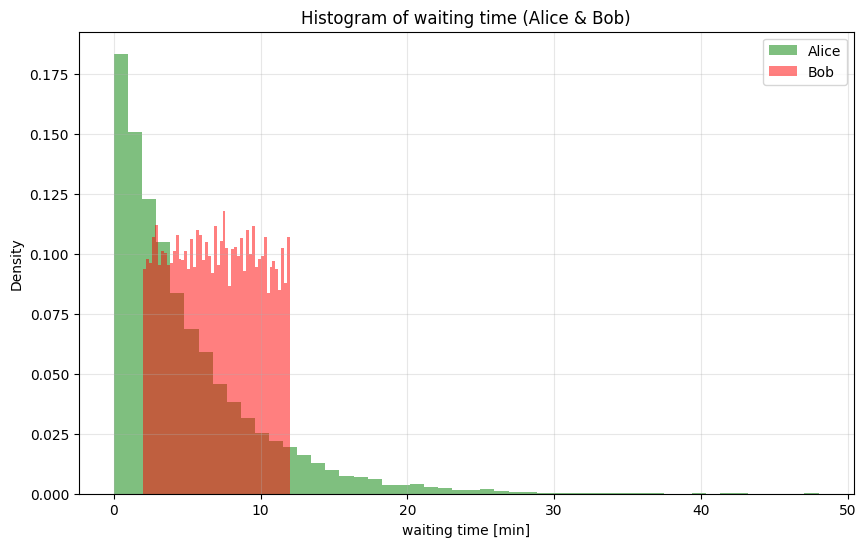

In [9]:
#code here
t_a=np.random.exponential(scale=1/lambda_val,size=N)
t_b=2+np.random.uniform(0,10,size=N)
P_a_win=np.mean(t_a<t_b)
t_diff=t_a-t_b
mean_t_diff=np.mean(t_diff)
print(f"P_Alice_wins={P_a_win:.4f}\n")
print(f"mean_of_diff_of_t_Alice_Bob={mean_t_diff:.4f}\n")
plt.figure(figsize=(10,6))
plt.hist(t_a,bins=50,alpha=0.5,label='Alice',color='green',density=True)
plt.hist(t_b,bins=50,alpha=0.5,label='Bob',color='red',density=True)
plt.title("Histogram of waiting time (Alice & Bob)")
plt.xlabel("waiting time [min]")
plt.ylabel("Density")
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()

# Question 2

In this homework, you will explore one of the most surprising results in probability theory: the **Birthday Paradox**.  
The paradox states that in a group of just 23 people, the probability that *at least two people share the same birthday* exceeds 50%.

You will:
- Simulate random birthdays using Python
- Estimate the probability empirically
- Compare it with the analytical (exact) probability
- Visualize the relationship between group size and probability

### Part (a): Simulate Random Birthdays

Write a function that simulates birthdays for `n` people.  
Assume birthdays are uniformly distributed across 365 days.


In [8]:
def generate_birthdays(n):
    """
    Generate n random birthdays (as integers from 1 to 365).
    """
    birthdays = np.random.uniform(1,366,n)
    birthdays = birthdays.astype(int)
    return birthdays

# Test your function:
print(generate_birthdays(10))

[ 79 175 307 318 269 198 172 234 280  53]


### Part (b): Check if there's a shared birthday

Write a function that checks whether at least two people in a group share the same birthday.


In [9]:
def has_shared_birthday(birthdays):
    """
    Returns True if there is a shared birthday, False otherwise.
    """
    result=False
    for i in range(0,len(birthdays),1):
        for j in range(0,len(birthdays),1):
            if birthdays[i]==birthdays[j] and i!=j:
                result=True

    return result

# Test your function:
print(has_shared_birthday(generate_birthdays(10)))


False


### Part (c): Estimate the probability empirically

We can estimate the probability that a shared birthday occurs by simulating many groups of `n` people and computing the fraction of groups with at least one match.


In [10]:
def estimate_probability(n, trials=10000):
    """
    Estimate the probability of at least one shared birthday
    among n people using Monte Carlo simulation.
    """
    count=0
    for i in range(trials):
        brithDays = generate_birthdays(n)
        if has_shared_birthday(brithDays):
            count+=1
    return count/trials

# Example: Probability for 23 people
prob_23 = estimate_probability(23)
print(f"Estimated probability for 23 people: {prob_23:.3f}")


Estimated probability for 23 people: 0.511


### Part (d): Compute the analytical probability

The exact probability that **no** two people share a birthday is:

$$
P(\text{no match}) = \prod_{k=0}^{n-1} \frac{365 - k}{365}
$$

Thus, the probability of **at least one match** is:

$$
P(\text{match}) = 1 - P(\text{no match})
$$

Implement this formula for arbitrary group sizes.


In [11]:
def analytical_probability(n):
    """
    Compute the exact probability that at least two people share a birthday.
    """
    p_no_match=1.0
    for i in range(0,n,1):
        p_no_match=p_no_match*(365-i)/365
    return 1-p_no_match
# Test
print(f"Analytical probability for 23 people: {analytical_probability(23):.3f}")


Analytical probability for 23 people: 0.507


### Part (e): Visualization

Plot both the empirical (simulated) and analytical probabilities
as functions of the group size `n` (from 2 to 60).


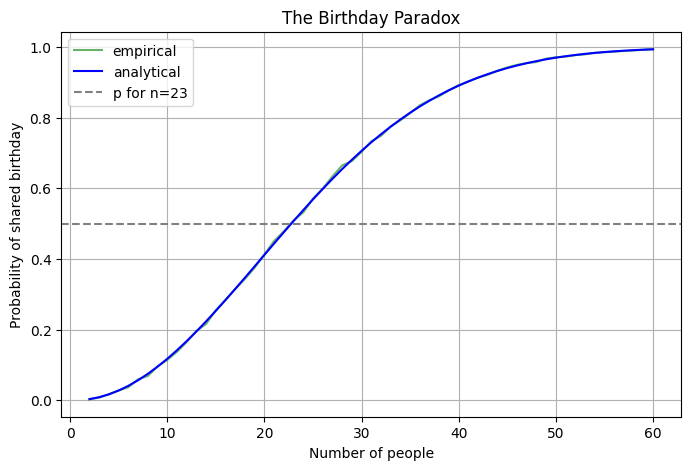

In [14]:
import matplotlib.pyplot as plt

group_sizes = range(2, 61)
empirical_probs = [estimate_probability(n) for n in group_sizes]
analytical_probs = [analytical_probability(n) for n in group_sizes]

plt.figure(figsize=(8, 5))
plt.plot(group_sizes,empirical_probs,label="empirical",color='green',alpha=0.6)
plt.plot(group_sizes,analytical_probs,label="analytical",color='blue')
plt.axhline(0.5, linestyle='--', color='gray',label='p for n=23')
plt.xlabel('Number of people')
plt.ylabel('Probability of shared birthday')
plt.title('The Birthday Paradox')
plt.legend()
plt.grid(True)
plt.show()


### Part (f): Discussion

Answer the following questions.

1. How many people are needed for the probability to exceed 50%?
2. How do the empirical and analytical curves compare?
3. What assumptions are made in this model, and how could they affect real-world scenarios?


**[Answers]**

# Question 3

## Modeling Exponential Forgetting
 In this homework, you will simulate exponential forgetting and understand how memory retention decreases over time. The task involves modeling this process using a Python program, applying probability concepts, and creating visualizations to aid your understanding.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon, norm


### Part (a)

This function models the forgetting process over time. We use the exponential decay formula:

$$
F(t)= e^{-λt}
$$ 

Where
$t$
 is the time and
$\lambda$
 is the forgetting rate. The forgetting rate controls how fast memory fades over time. A larger value of
$\lambda$
 means faster forgetting.

In [16]:
# FIX
def exponential_forgetting(t, lambda_val):
    """
    Models the exponential forgetting process.

    Parameters:
    t (array-like): Array of time values.
    lambda_val (float): Forgetting rate, lambda.

    Returns:
    numpy.ndarray: Exponential forgetting values at each time step.
    """
    return np.exp(-lambda_val * t)


Plot the forgetting curves for different $\lambda$ values on the same graph.


<>:12: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:13: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:14: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:12: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:13: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:14: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\Asus\AppData\Local\Temp\ipykernel_7696\3759290061.py:12: SyntaxWarn

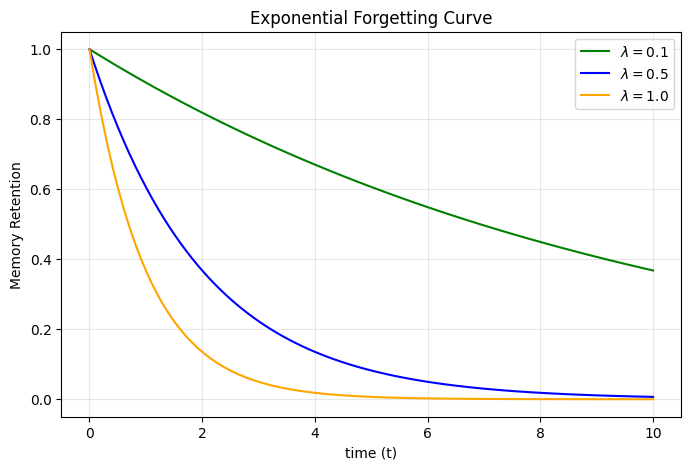

In [17]:
# (TODO): Plot the forgetting curve for different lambda values

# Define time array (for example, from 0 to 10 in steps of 0.1)
time = np.linspace(0, 10, 100)

# Forgetting rates to visualize
lambda_values = [0.1, 0.5, 1.0]

# (TODO)
# Plotting the forgetting curves
plt.figure(figsize=(8,5))
plt.plot(time, exponential_forgetting(time, lambda_values[0]), label=f'$\lambda = {lambda_values[0]}$',color='green')
plt.plot(time,exponential_forgetting(time, lambda_values[1]), label=f'$\lambda = {lambda_values[1]}$',color='blue')
plt.plot(time,exponential_forgetting(time, lambda_values[2]), label=f'$\lambda = {lambda_values[2]}$',color='orange')
plt.title('Exponential Forgetting Curve')
plt.xlabel('time (t)')
plt.ylabel('Memory Retention')
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()

### Part (b)

Generate synthetic memory retention data, then fit an exponential decay model to it and visualize both the data and fitted curve.


Our A=1.0035
Our lambda=0.4879


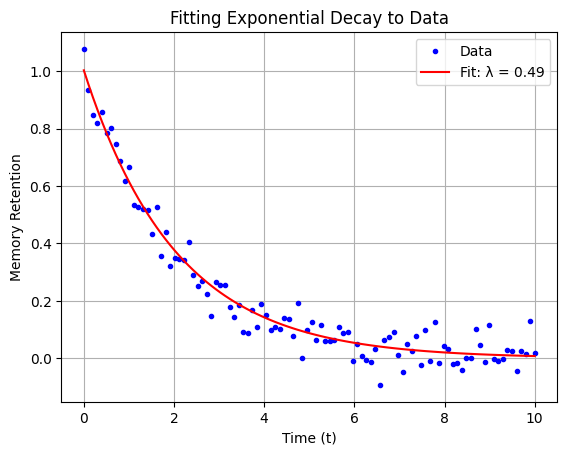

In [21]:
# TO DO: Fit exponential distributions to real data
from scipy.optimize import curve_fit

# Exponential decay function to fit data
def exp_fit(t, A, lambda_val):
    return A * np.exp(-lambda_val * t)
# Example synthetic data (time vs. memory retention)

time = np.linspace(0, 10, 100)
our_lambda = 0.5
our_A=1.0
noise = np.random.normal(0,0.05,size=len(time))
# (TODO) Fit exponential model and memory_data
memory_data = our_A*np.exp(-1*our_lambda*time) + noise
params,cov = curve_fit(exp_fit,time,memory_data)
fitted_A,fitted_l=params
print(f'Our A={fitted_A:.4f}')
print(f'Our lambda={fitted_l:.4f}')
# Plot data and fit
plt.plot(time, memory_data, 'b.', label='Data')
plt.plot(time, exp_fit(time, *params), 'r-', label=f'Fit: λ = {params[1]:.2f}')
plt.title("Fitting Exponential Decay to Data")
plt.xlabel("Time (t)")
plt.ylabel("Memory Retention")
plt.legend()
plt.grid(True)
plt.show()

# Question 4

**Exploring Distribution Closure Under Addition**

When two independent random variables from the **same family** are added together, sometimes the result still belongs to that family—and sometimes it doesn’t.

Your goal in this assignment is to **experimentally investigate** this property for three continuous distributions: **Normal**, **Gamma**, and **Exponential**.



### part (a)



1. **Generate Samples**

   * Simulate large samples (e.g., $N = 100000$) from independent random variables $X$ and $Y$ for each of the following cases:

     * Normal: $X \sim \mathcal{N}(\mu_1, \sigma_1^2) ), ( Y \sim \mathcal{N}(\mu_2, \sigma_2^2)$
     * Gamma: $X \sim \Gamma(k_1, \theta) ), ( Y \sim \Gamma(k_2, \theta)$
     * Exponential: $X \sim \text{Exp}(\lambda_1) ), ( Y \sim \text{Exp}(\lambda_2)$

   Choose different parameters for ( X ) and ( Y ) in each family.

2. **Form the Sum**

   * For each case, compute $ S = X + Y $.

3. **Define a Theoretical “Target” Distribution**

   * For Normal and Gamma, the sum $S$ should, in theory, still follow the same distribution family with specific new parameters.
   * For the Exponential case, choose a single exponential distribution that *best approximates* $S$ (for example, by matching the mean).


In [25]:
# Random seed for reproducibility
np.random.seed(42)
N = 100000

# ===============================================================
# 1. NORMAL DISTRIBUTION
# ===============================================================
mu1, sigma1 = 0,1
mu2, sigma2 = 2,2

Xn = np.random.normal(mu1,sigma1,N)
Yn = np.random.normal(mu2,sigma2,N)
Sn = Xn + Yn

# Theoretical target: sum of normals -> normal
mu_sum = mu1 + mu2
sigma_sum = np.sqrt(sigma1**2 + sigma2**2)
Zn = np.random.normal(mu_sum,sigma_sum,N)
# ===============================================================
# 2. GAMMA DISTRIBUTION (shape-scale parameterization)
# ===============================================================
k1, k2, theta = 2.0,3.0,2.0

Xg = np.random.gamma(k1,theta,N)
Yg = np.random.gamma(k2,theta,N)
Sg = Xg + Yg

# Theoretical target: same scale => Gamma(shape1+shape2, same theta)
k_sum = k1 + k2
Zg = np.random.gamma(k_sum,theta,N)
# ===============================================================
# 3. EXPONENTIAL DISTRIBUTION
# ===============================================================
lam1, lam2 = 1.0,2.0
Xe = np.random.exponential(scale=1/lam1,size=N)
Ye = np.random.exponential(scale=1/lam2,size=N)
Se = Xe + Ye

# Theoretical "target" (approximation): match mean -> Exp(rate_fit)
rate_fit = 1/(1/lam1 + 1/lam2)
Ze = np.random.exponential(scale=1/rate_fit,size=N)

### part (b)

1. **Estimate PDFs**

   * Using histogram or kernel density estimation, approximate the PDF of $S$ and the PDF of the theoretical or fitted target distribution.

2. **Compare Using RMSE**

   * Compute the **Root Mean Squared Error (RMSE)** between the estimated PDFs of $S$ and the target distribution on a common grid.
     $$
     \text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (p_S(x_i) - p_Z(x_i))^2}
     $$
   * RMSE gives a direct numerical measure of how different the two estimated densities are.




In [33]:
from scipy.stats import norm, gamma, expon
# Helper: estimate PDF using normalized histogram
def estimate_pdf(samples, bins=300, range_=None):
    if range_ is None:
        range_=(np.min(samples),np.max(samples))
    counts, bin_edges = np.histogram(samples, bins=bins, range=range_,density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:])/2.
    return bin_centers , counts

# Helper: compute RMSE between two PDFs on same grid
def rmse(p, q):
    return np.sqrt(np.mean((p-q)**2))

# ===============================================================
# 1. NORMAL DISTRIBUTION (TODO)
# ===============================================================
Xn, Yn = estimate_pdf(Sn)

Yn_theo=norm.pdf(Xn,loc=mu_sum,scale=sigma_sum)

rmse_norm=rmse(Yn,Yn_theo)


# ===============================================================
# 2. GAMMA DISTRIBUTION (shape-scale parameterization) (TODO)
# ===============================================================
Xg, Yg = estimate_pdf(Sg)
Yg_theo=gamma.pdf(Xg,a=k_sum,scale=theta)
rmse_gamma=rmse(Yg,Yg_theo)

# ===============================================================
# 3. EXPONENTIAL DISTRIBUTION (TODO)
# ===============================================================
Xe,Ye=estimate_pdf(Se)
Ye_theo=expon.pdf(Xe,scale=sigma_sum)
rmse_expon=rmse(Ye,Ye_theo)


### part (c)

1. **Visualization and Discussion**

   * Plot both estimated PDFs for each distribution family on the same graph.
   * Report the RMSE values and interpret the results:

     * Which distributions appear to stay in the same family after addition?
     * Which one clearly does not?
     * Does the RMSE reflect what you see in the plots?

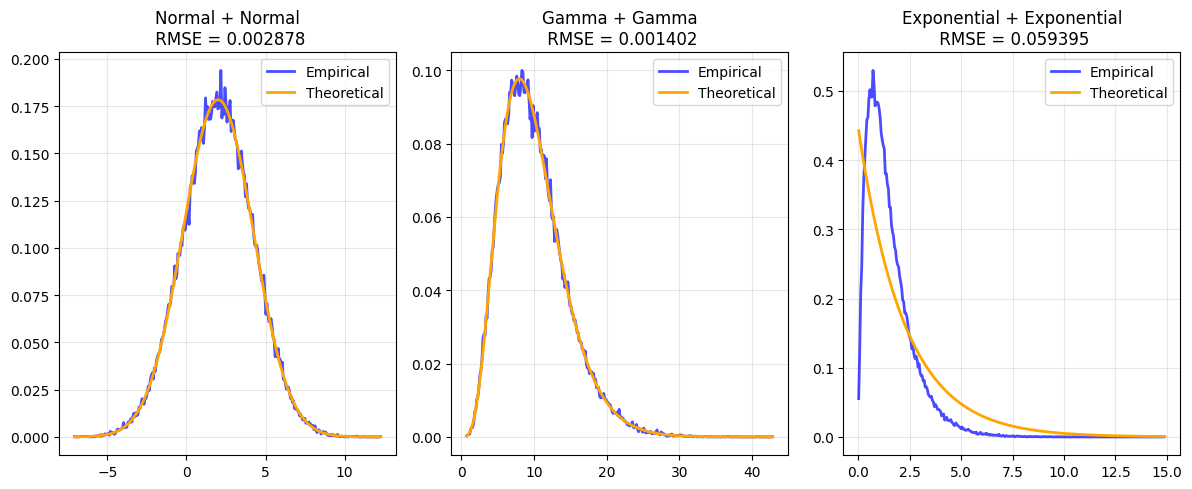


RMSE summary table:
----------------------------------------
Normal RMSE: 0.00288
Gamma RMSE: 0.00140
Exponential RMSE: 0.05940


In [32]:
# For consistent plotting
def plot_pdfs(x, p_emp, p_theo, title, rmse_val,ax):
    ax.plot(x, p_emp, label='Empirical', color='blue',linewidth=2,alpha=0.7)
    ax.plot(x, p_theo, label='Theoretical', color='orange',linewidth=2)
    ax.set_title(f"{title}\n RMSE = {rmse_val:.6f}")
    ax.legend()
    ax.grid(True,alpha=0.3)
# ===============================================================
# Plot everything (TODO)
# ===============================================================
fig, ax = plt.subplots(1,3,figsize=(12,5))
plot_pdfs(Xn,Yn,Yn_theo,"Normal + Normal",rmse_norm,ax[0])
plot_pdfs(Xg,Yg,Yg_theo,"Gamma + Gamma",rmse_gamma,ax[1])
plot_pdfs(Xe,Ye,Ye_theo,"Exponential + Exponential",rmse_expon,ax[2])
plt.tight_layout()
plt.show()
# ===============================================================
# Print summary table (TODO)
# ===============================================================
print("\nRMSE summary table:")
print("-"*40)
print(f'Normal RMSE: {rmse_norm:.5f}')
print(f'Gamma RMSE: {rmse_gamma:.5f}')
print(f'Exponential RMSE: {rmse_expon:.5f}')